In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

data = {
    'right_jab': {'right_jab': 9, 'rest': 1},
    'right_hook': {'right_hook': 10},
    'right_uppercut': {'right_uppercut': 9, 'right_hook': 1},
    'left_jab': {'left_jab': 9, 'rest': 1},
    'left_hook': {'left_hook': 10},
    'left_uppercut': {'left_uppercut': 8, 'left_hook': 2}
}

# Convert nested dictionary into a confusion matrix
cm_df = pd.DataFrame(data).T.fillna(0).astype(int)

# Ensure all classes appear in the same order
labels = [
    'left_hook',
    'left_jab',
    'left_uppercut',
    'rest',
    'right_hook',
    'right_jab',
    'right_uppercut',
]

cm_df = cm_df.reindex(
    index=labels,
    columns=labels,
    fill_value=0
)

print(cm_df)

                left_hook  left_jab  left_uppercut  rest  right_hook  \
left_hook              10         0              0     0           0   
left_jab                0         9              0     1           0   
left_uppercut           2         0              8     0           0   
rest                    0         0              0     0           0   
right_hook              0         0              0     0          10   
right_jab               0         0              0     1           0   
right_uppercut          0         0              0     0           1   

                right_jab  right_uppercut  
left_hook               0               0  
left_jab                0               0  
left_uppercut           0               0  
rest                    0               0  
right_hook              0               0  
right_jab               9               0  
right_uppercut          0               9  


Overall Accuracy: 0.9166666666666666
Classification Report:
                 precision    recall  f1-score   support

     left_hook       0.83      1.00      0.91        10
      left_jab       1.00      0.90      0.95        10
 left_uppercut       1.00      0.80      0.89        10
    right_hook       0.91      1.00      0.95        10
     right_jab       1.00      0.90      0.95        10
right_uppercut       1.00      0.90      0.95        10

     micro avg       0.95      0.92      0.93        60
     macro avg       0.96      0.92      0.93        60
  weighted avg       0.96      0.92      0.93        60



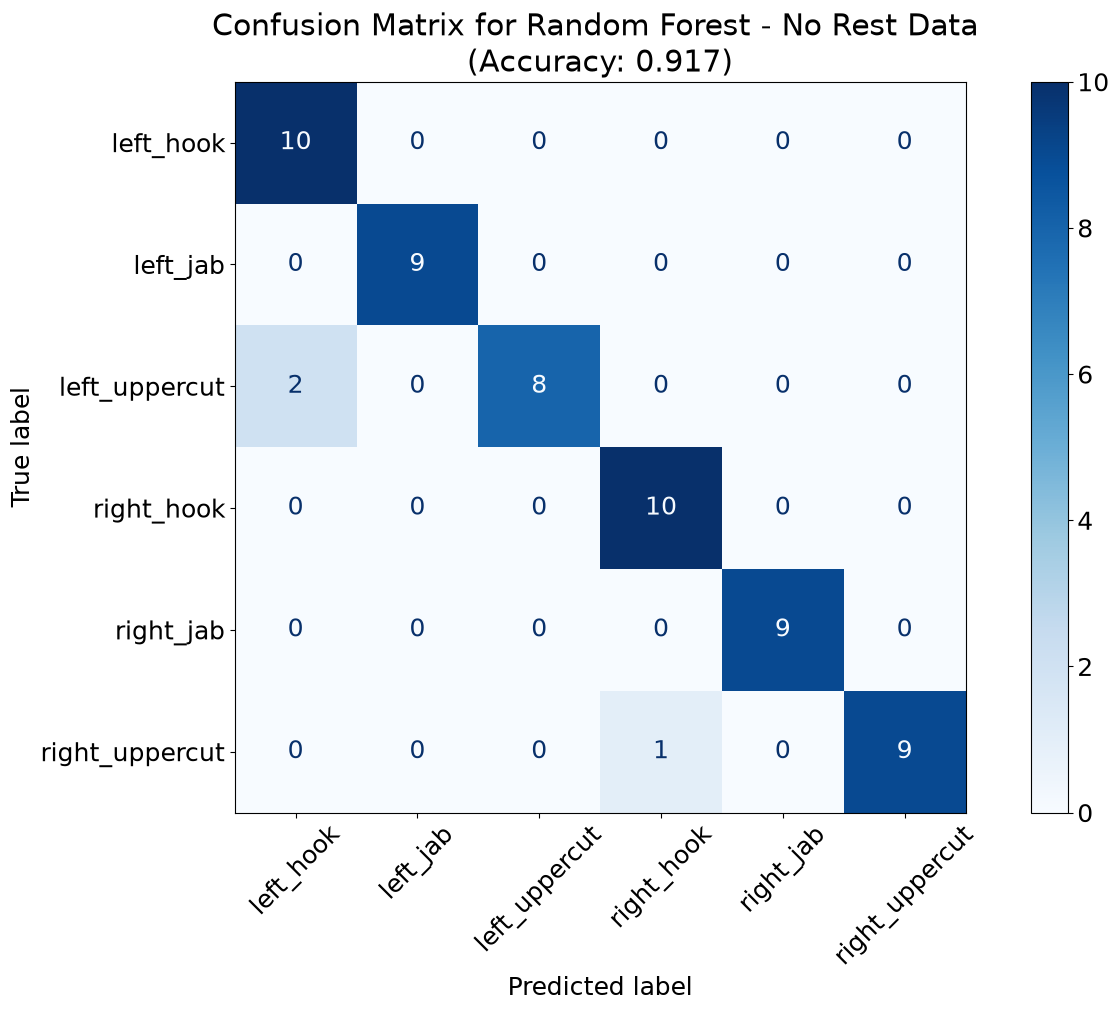

In [11]:
plt.rcParams.update({'font.size': 18}) #

cm = cm_df.to_numpy()

# Calculate overall accuracy
accuracy = np.trace(cm) / cm.sum()

# Exclude the rest class from the displayed metrics
# while retaining rest predictions in the accuracy calculation
non_rest_labels = [label for label in labels if label != 'rest']
non_rest_indices = [labels.index(label) for label in non_rest_labels]

cm_no_rest = cm[np.ix_(non_rest_indices, non_rest_indices)]

# Classification metrics for the non-rest classes
true_counts = []
pred_counts = []

for i, true_label in enumerate(labels):
    for j, pred_label in enumerate(labels):
        count = cm[i, j]
        if count:
            true_counts.extend([true_label] * count)
            pred_counts.extend([pred_label] * count)

mask = [
    true != 'rest'
    for true, pred in zip(true_counts, pred_counts)
]

true_no_rest = np.array(true_counts)[mask]
pred_no_rest = np.array(pred_counts)[mask]

print("Overall Accuracy:", accuracy)

print(
    "Classification Report:\n",
    classification_report(
        true_no_rest,
        pred_no_rest,
        labels=non_rest_labels,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_no_rest,
    display_labels=non_rest_labels
)

disp.plot(ax=ax, xticks_rotation=45, cmap=plt.cm.Blues)

ax.set_title(f"Confusion Matrix for Random Forest - No Rest Data \n(Accuracy: {accuracy:.3f})")

plt.savefig("figures/fr_darragh_real-time_scoring_cm.png", dpi=300)
plt.show()

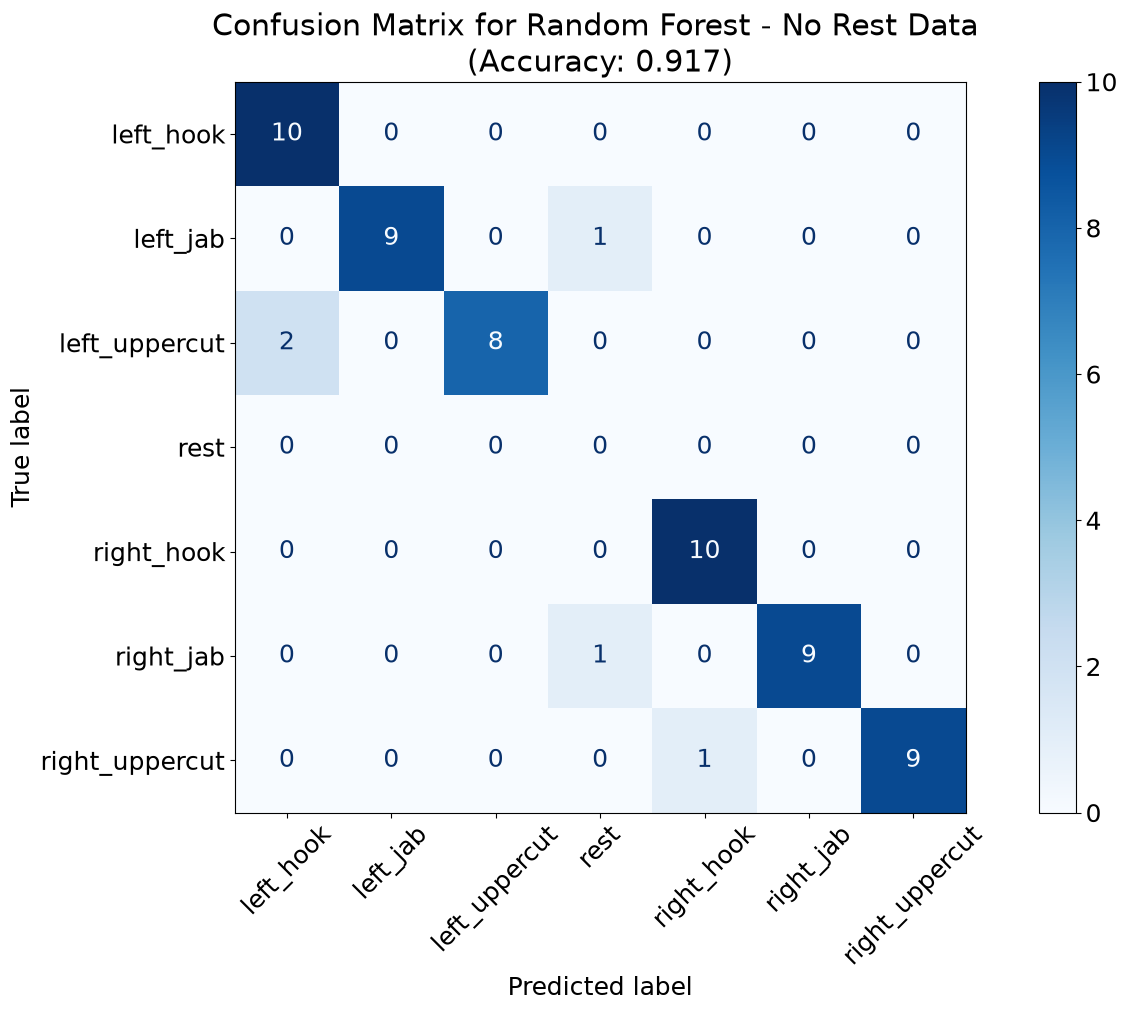

In [13]:
cm_display = cm.copy()

rest_idx = labels.index('rest')

# Hide correct rest predictions
cm_display[rest_idx, rest_idx] = 0

fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_display,
    display_labels=labels
)

disp.plot(ax=ax, xticks_rotation=45, cmap=plt.cm.Blues)

ax.set_title(f"Confusion Matrix for Random Forest - No Rest Data \n(Accuracy: {accuracy:.3f})")

plt.savefig("figures/rf_darragh_real-time_scoring_cm.png", dpi=300)

plt.show()